In [2]:
#Cell 1: Setup
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import json
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from src.config import CLASSES, FIG_DIR, MODELS_DIR, RESULTS_DIR, SEED
from src.dataset import get_loaders
from src.models import build_mobilenet_v3, build_resnet18, count_parameters
from src.train import evaluate, fit


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_loader, val_loader, test_loader = get_loaders(batch_size=32)
print("Batches -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

Device: cpu
Batches -> train: 48 | val: 11 | test: 11


In [3]:
#Cell 2: Inspect the two pretrained models (no training yet)
for name, builder in [("MobileNetV3", build_mobilenet_v3), ("ResNet18", build_resnet18)]:
    m = builder(num_classes=len(CLASSES), freeze_backbone=True)
    total = sum(p.numel() for p in m.parameters())
    print(f"{name:12s} total params: {total:>11,} | trainable: {count_parameters(m):>10,}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\kalpa/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100.0%


MobileNetV3  total params:   4,205,875 | trainable:  1,233,923
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\kalpa/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


ResNet18     total params:  11,178,051 | trainable:      1,539


In [4]:
#Cell 3: Train MobileNetV3 (frozen backbone)
set_seed()
mobilenet = build_mobilenet_v3(num_classes=len(CLASSES), freeze_backbone=True).to(device)

EPOCHS = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    [p for p in mobilenet.parameters() if p.requires_grad],   # only the trainable head
    lr=1e-3, weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

mobilenet_history = fit(
    mobilenet, train_loader, val_loader, criterion, optimizer, device,
    epochs=EPOCHS, scheduler=scheduler,
    save_path=MODELS_DIR / "mobilenet_v3_frozen.pth",
)

with open(RESULTS_DIR / "mobilenet_v3_frozen_history.json", "w") as f:
    json.dump(mobilenet_history, f, indent=2)

Epoch 01/10 | train loss 0.209 acc 0.922 | val loss 1.440 acc 0.610 f1 0.507 | 30s
Epoch 02/10 | train loss 0.076 acc 0.971 | val loss 0.211 acc 0.920 f1 0.859 | 36s
Epoch 03/10 | train loss 0.175 acc 0.948 | val loss 0.085 acc 0.966 f1 0.931 | 24s
Epoch 04/10 | train loss 0.104 acc 0.967 | val loss 0.079 acc 0.975 f1 0.950 | 34s
Epoch 05/10 | train loss 0.059 acc 0.978 | val loss 0.068 acc 0.978 f1 0.962 | 28s
Epoch 06/10 | train loss 0.077 acc 0.975 | val loss 0.036 acc 0.988 f1 0.979 | 27s
Epoch 07/10 | train loss 0.054 acc 0.980 | val loss 0.029 acc 0.991 f1 0.987 | 27s
Epoch 08/10 | train loss 0.039 acc 0.987 | val loss 0.029 acc 0.988 f1 0.985 | 37s
Epoch 09/10 | train loss 0.032 acc 0.989 | val loss 0.027 acc 0.988 f1 0.985 | 25s
Epoch 10/10 | train loss 0.031 acc 0.988 | val loss 0.027 acc 0.988 f1 0.985 | 28s
Best val macro F1: 0.987


In [5]:
#Cell 4: Test MobileNetV3 and save the results
from sklearn.metrics import classification_report

short = [c.replace("Potato___", "").replace("_", " ") for c in CLASSES]


def test_and_save(model, name):
    """Evaluate a trained model on the test set and save the results."""
    test_loss, test_acc, test_f1, preds, labels = evaluate(model, test_loader, criterion, device)
    print(f"{name} | test accuracy: {test_acc:.3f} | test macro F1: {test_f1:.3f}\n")
    print(classification_report(labels, preds, target_names=short, digits=3))

    results = {
        "model": name,
        "parameters_trainable": count_parameters(model),
        "parameters_total": sum(p.numel() for p in model.parameters()),
        "test_accuracy": test_acc,
        "test_macro_f1": test_f1,
        "test_preds": preds,
        "test_labels": labels,
    }
    with open(RESULTS_DIR / f"{name}_test_results.json", "w") as f:
        json.dump(results, f, indent=2)
    return results


mobilenet_results = test_and_save(mobilenet, "mobilenet_v3_frozen")

mobilenet_v3_frozen | test accuracy: 0.981 | test macro F1: 0.968

              precision    recall  f1-score   support

Early blight      0.993     0.987     0.990       150
 Late blight      0.974     0.987     0.980       150
     healthy      0.955     0.913     0.933        23

    accuracy                          0.981       323
   macro avg      0.974     0.962     0.968       323
weighted avg      0.981     0.981     0.981       323



In [6]:
#Cell 5: Train ResNet18 (frozen backbone)
set_seed()
resnet = build_resnet18(num_classes=len(CLASSES), freeze_backbone=True).to(device)

optimizer = torch.optim.Adam(
    [p for p in resnet.parameters() if p.requires_grad],
    lr=1e-3, weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

resnet_history = fit(
    resnet, train_loader, val_loader, criterion, optimizer, device,
    epochs=EPOCHS, scheduler=scheduler,
    save_path=MODELS_DIR / "resnet18_frozen.pth",
)

with open(RESULTS_DIR / "resnet18_frozen_history.json", "w") as f:
    json.dump(resnet_history, f, indent=2)


Epoch 01/10 | train loss 0.535 acc 0.813 | val loss 0.349 acc 0.879 f1 0.636 | 68s
Epoch 02/10 | train loss 0.295 acc 0.917 | val loss 0.203 acc 0.944 f1 0.844 | 73s
Epoch 03/10 | train loss 0.220 acc 0.938 | val loss 0.212 acc 0.923 f1 0.733 | 57s
Epoch 04/10 | train loss 0.187 acc 0.948 | val loss 0.154 acc 0.954 f1 0.906 | 62s
Epoch 05/10 | train loss 0.155 acc 0.965 | val loss 0.135 acc 0.963 f1 0.930 | 69s
Epoch 06/10 | train loss 0.144 acc 0.959 | val loss 0.125 acc 0.975 f1 0.947 | 73s
Epoch 07/10 | train loss 0.145 acc 0.962 | val loss 0.127 acc 0.966 f1 0.932 | 73s
Epoch 08/10 | train loss 0.133 acc 0.967 | val loss 0.122 acc 0.960 f1 0.928 | 73s
Epoch 09/10 | train loss 0.121 acc 0.974 | val loss 0.119 acc 0.966 f1 0.941 | 81s
Epoch 10/10 | train loss 0.135 acc 0.963 | val loss 0.114 acc 0.972 f1 0.954 | 93s
Best val macro F1: 0.954


In [7]:
#test ResNet18
resnet_results = test_and_save(resnet, "resnet18_frozen")

resnet18_frozen | test accuracy: 0.969 | test macro F1: 0.935

              precision    recall  f1-score   support

Early blight      1.000     0.973     0.986       150
 Late blight      0.938     1.000     0.968       150
     healthy      1.000     0.739     0.850        23

    accuracy                          0.969       323
   macro avg      0.979     0.904     0.935       323
weighted avg      0.971     0.969     0.968       323



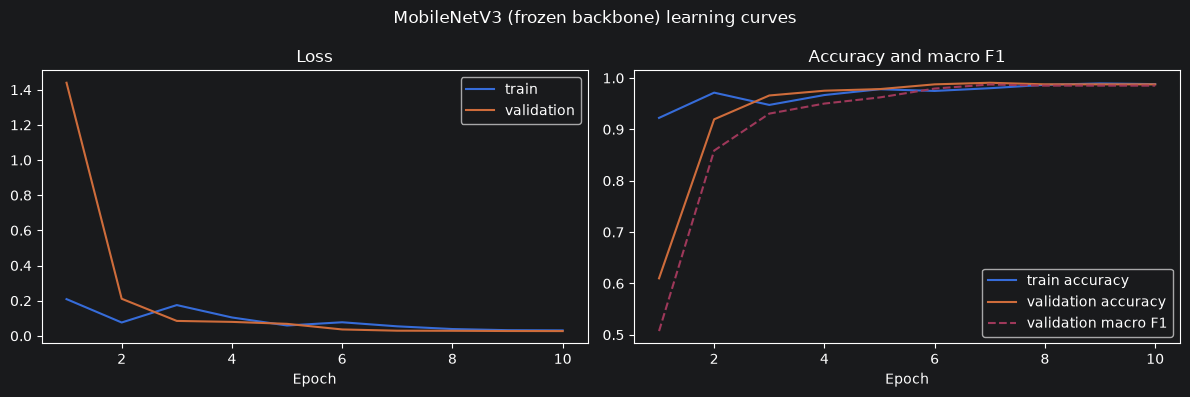

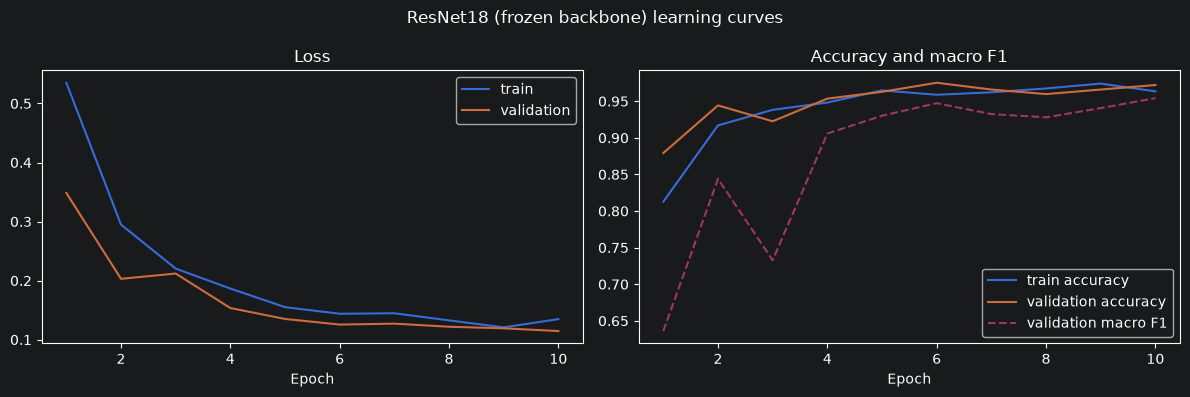

In [9]:
#New cell: learning curves for both models
def plot_history(history, title, filename):
    """Plot loss and accuracy/F1 curves for one training run."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="train accuracy")
    axes[1].plot(epochs, history["val_acc"], label="validation accuracy")
    axes[1].plot(epochs, history["val_f1"], label="validation macro F1", linestyle="--")
    axes[1].set_title("Accuracy and macro F1")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=200)
    plt.show()


plot_history(mobilenet_history, "MobileNetV3 (frozen backbone) learning curves",
             "mobilenet_v3_frozen_learning_curves.png")
plot_history(resnet_history, "ResNet18 (frozen backbone) learning curves",
             "resnet18_frozen_learning_curves.png")